In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
from collections import Counter

ROOT = "/kaggle/input"
for dirpath, dirs, files in os.walk(ROOT):
    depth = dirpath[len(ROOT):].count(os.sep)
    if depth > 4:
        dirs[:] = []
        continue
    if files:
        ext = Counter(os.path.splitext(f)[1].lower() for f in files)
        print(f"{dirpath}  ->  {dict(ext)}")
    else:
        print(dirpath)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/akaashmahe4
/kaggle/input/datasets/akaashmahe4/fassd-rs
/kaggle/input/datasets/akaashmahe4/fassd-rs/annotations
/kaggle/input/datasets/akaashmahe4/fassd-rs/images  ->  {'.tif': 2223}


In [2]:
import glob

for pat in ["*.txt", "*.xml", "*.json"]:
    found = glob.glob(f"{ROOT}/**/{pat}", recursive=True)
    print(pat, len(found), found[:2])

txts = [f for f in glob.glob(f"{ROOT}/**/*.txt", recursive=True) if "label" in f.lower()]
if txts:
    print("\nSample:", txts[0])
    print(open(txts[0]).read()[:300])

*.txt 2226 ['/kaggle/input/datasets/akaashmahe4/fassd-rs/annotations/YOLO_RS_RGB/val.txt', '/kaggle/input/datasets/akaashmahe4/fassd-rs/annotations/YOLO_RS_RGB/test.txt']
*.xml 2223 ['/kaggle/input/datasets/akaashmahe4/fassd-rs/annotations/VOC_RS_RGB/Annotations/neitherFireNorSmoke_RS000455.xml', '/kaggle/input/datasets/akaashmahe4/fassd-rs/annotations/VOC_RS_RGB/Annotations/smoke_RS000999.xml']
*.json 4 ['/kaggle/input/datasets/akaashmahe4/fassd-rs/annotations/COCO_RS_RGB/Annotations/train.json', '/kaggle/input/datasets/akaashmahe4/fassd-rs/annotations/COCO_RS_RGB/Annotations/test.json']

Sample: /kaggle/input/datasets/akaashmahe4/fassd-rs/annotations/YOLO_RS_RGB/labels/neitherFireNorSmoke_RS000753.txt



In [3]:
import os, glob, cv2, numpy as np
from collections import Counter, defaultdict

BASE = "/kaggle/input/datasets/akaashmahe4/fassd-rs"
YOLO = f"{BASE}/annotations/YOLO_RS_RGB"
IMGS = f"{BASE}/images"

# 1) Split lists
for s in ["train", "val", "test"]:
    p = f"{YOLO}/{s}.txt"
    if os.path.exists(p):
        lines = [l.strip() for l in open(p) if l.strip()]
        print(s, len(lines), "| first 2:", lines[:2])
    else:
        print(s, "MISSING")

# 2) Class IDs vs filename prefix, plus instance counts
cls_by_prefix = defaultdict(Counter)
inst = Counter()
empty = 0
for f in glob.glob(f"{YOLO}/labels/*.txt"):
    prefix = os.path.basename(f).split("_RS")[0]
    ids = [l.split()[0] for l in open(f) if l.strip()]
    if not ids:
        empty += 1
    for i in ids:
        cls_by_prefix[prefix][i] += 1
        inst[i] += 1
print("\nInstances per class id:", dict(inst))
print("Empty label files:", empty)
for k, v in cls_by_prefix.items():
    print(f"  {k}: {dict(v)}")

# 3) Image format check
tifs = sorted(glob.glob(f"{IMGS}/*.tif"))
print("\nTotal tifs:", len(tifs))
shapes = Counter()
for p in tifs[:50]:
    im = cv2.imread(p, cv2.IMREAD_UNCHANGED)
    shapes[(None if im is None else (im.shape, str(im.dtype)))] += 1
print(shapes)

train 1112 | first 2: ['./images/smoke_RS000491.tif', './images/smoke_RS000116.tif']
val 741 | first 2: ['./images/smoke_RS000382.tif', './images/smoke_RS000820.tif']
test 370 | first 2: ['./images/smoke_RS000421.tif', './images/smoke_RS000202.tif']

Instances per class id: {'1': 2770}
Empty label files: 888
  smoke: {'1': 2770}

Total tifs: 2223


[ WARN:0@6.343] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33550 (0x830e) encountered
[ WARN:0@6.343] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33922 (0x8482) encountered
[ WARN:0@6.343] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34735 (0x87af) encountered
[ WARN:0@6.343] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34736 (0x87b0) encountered
[ WARN:0@6.343] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34737 (0x87b1) encountered
[ WARN:0@6.412] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33550 (0x830e) encountered
[ WARN:0@6.412] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33922 (0x8482) encountered
[ WARN:0@6.412] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34735 (0x87af) encountered
[ WARN:0

Counter({((1000, 1000, 3), 'uint8'): 50})


[ WARN:0@9.077] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33550 (0x830e) encountered
[ WARN:0@9.077] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33922 (0x8482) encountered
[ WARN:0@9.077] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34735 (0x87af) encountered
[ WARN:0@9.077] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34736 (0x87b0) encountered
[ WARN:0@9.077] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34737 (0x87b1) encountered
[ WARN:0@9.130] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33550 (0x830e) encountered
[ WARN:0@9.130] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 33922 (0x8482) encountered
[ WARN:0@9.130] global grfmt_tiff.cpp:122 TIFF_Warning TIFFReadDirectory: Unknown field with tag 34735 (0x87af) encountered
[ WARN:0

In [4]:
import os, glob, cv2
from collections import Counter, defaultdict

cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_ERROR)

BASE = "/kaggle/input/datasets/akaashmahe4/fassd-rs"
YOLO = f"{BASE}/annotations/YOLO_RS_RGB"
IMGS = f"{BASE}/images"

# 1) Split lists
for s in ["train", "val", "test"]:
    p = f"{YOLO}/{s}.txt"
    lines = [l.strip() for l in open(p) if l.strip()] if os.path.exists(p) else []
    print(f"{s}: {len(lines)} | first 2: {lines[:2]}")

# 2) Class IDs vs filename prefix
cls_by_prefix = defaultdict(Counter)
inst, empty = Counter(), 0
for f in glob.glob(f"{YOLO}/labels/*.txt"):
    prefix = os.path.basename(f).split("_RS")[0]
    ids = [l.split()[0] for l in open(f) if l.strip()]
    empty += (len(ids) == 0)
    for i in ids:
        cls_by_prefix[prefix][i] += 1
        inst[i] += 1
print("\nInstances per class id:", dict(inst))
print("Empty label files:", empty)
for k, v in cls_by_prefix.items():
    print(f"  {k}: {dict(v)}")

# 3) Image format
tifs = sorted(glob.glob(f"{IMGS}/*.tif"))
shapes = Counter()
for p in tifs[:50]:
    im = cv2.imread(p, cv2.IMREAD_UNCHANGED)
    shapes[None if im is None else (im.shape, str(im.dtype))] += 1
print("\nTotal tifs:", len(tifs))
print("Shape/dtype of first 50:", dict(shapes))

# 4) Georeferencing (if rasterio is available)
try:
    import rasterio
    with rasterio.open(tifs[0]) as src:
        print("\nCRS:", src.crs, "| bands:", src.count, "| bounds:", src.bounds)
except Exception as e:
    print("\nrasterio check skipped:", e)

train: 1112 | first 2: ['./images/smoke_RS000491.tif', './images/smoke_RS000116.tif']
val: 741 | first 2: ['./images/smoke_RS000382.tif', './images/smoke_RS000820.tif']
test: 370 | first 2: ['./images/smoke_RS000421.tif', './images/smoke_RS000202.tif']

Instances per class id: {'1': 2770}
Empty label files: 888
  smoke: {'1': 2770}

Total tifs: 2223
Shape/dtype of first 50: {((1000, 1000, 3), 'uint8'): 50}

CRS: EPSG:4326 | bands: 3 | bounds: BoundingBox(left=17.842877162352405, bottom=-32.80207243115273, right=17.932708690764358, top=-32.71224090274078)


In [5]:
import os, glob, shutil, csv, cv2
from collections import Counter
cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_ERROR)

BASE = "/kaggle/input/datasets/akaashmahe4/fassd-rs"
YOLO = f"{BASE}/annotations/YOLO_RS_RGB"
OUT  = "/kaggle/working/fasdd_rs_yolo"

try:
    import rasterio
except ImportError:
    rasterio = None

meta_rows = []
for split in ["train", "val", "test"]:
    os.makedirs(f"{OUT}/images/{split}", exist_ok=True)
    os.makedirs(f"{OUT}/labels/{split}", exist_ok=True)
    names = [os.path.basename(l.strip()) for l in open(f"{YOLO}/{split}.txt") if l.strip()]
    n_pos, n_inst, n_neg = 0, 0, 0
    for fn in names:
        stem = os.path.splitext(fn)[0]
        src_img = f"{BASE}/images/{fn}"
        # tif -> png (drops georef tags; we keep bounds in a CSV)
        im = cv2.imread(src_img, cv2.IMREAD_COLOR)
        cv2.imwrite(f"{OUT}/images/{split}/{stem}.png", im)
        # labels: remap class id 1 (smoke) -> 0 (single-class)
        lab_src = f"{YOLO}/labels/{stem}.txt"
        lines = [l.split() for l in open(lab_src)] if os.path.exists(lab_src) else []
        lines = [l for l in lines if l]
        with open(f"{OUT}/labels/{split}/{stem}.txt", "w") as f:
            for p in lines:
                assert p[0] == "1", f"unexpected class {p[0]} in {stem}"
                f.write("0 " + " ".join(p[1:]) + "\n")
        if lines: n_pos += 1; n_inst += len(lines)
        else: n_neg += 1
        # georeference
        if rasterio:
            with rasterio.open(src_img) as s:
                b = s.bounds
                meta_rows.append([stem, split, b.left, b.bottom, b.right, b.top])
    print(f"{split}: {len(names)} images | positive {n_pos} | negative {n_neg} | smoke instances {n_inst}")

if meta_rows:
    with open("/kaggle/working/fasdd_rs_georef.csv", "w", newline="") as f:
        w = csv.writer(f); w.writerow(["stem","split","left","bottom","right","top"]); w.writerows(meta_rows)

with open(f"{OUT}/data.yaml", "w") as f:
    f.write(f"path: {OUT}\ntrain: images/train\nval: images/val\ntest: images/test\nnc: 1\nnames:\n  0: smoke\n")
print(open(f"{OUT}/data.yaml").read())

# prefix check for the empty (negative) labels
pref = Counter(os.path.basename(f).split("_RS")[0] for f in glob.glob(f"{YOLO}/labels/*.txt")
               if not open(f).read().strip())
print("Prefixes of empty-label files:", dict(pref))

train: 1112 images | positive 668 | negative 444 | smoke instances 1380
val: 741 images | positive 445 | negative 296 | smoke instances 917
test: 370 images | positive 222 | negative 148 | smoke instances 473
path: /kaggle/working/fasdd_rs_yolo
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: smoke

Prefixes of empty-label files: {'neitherFireNorSmoke': 888}


In [6]:
!pip -q install ultralytics
from ultralytics import YOLO

model = YOLO("yolo11n.pt")
model.train(
    data="/kaggle/working/fasdd_rs_yolo/data.yaml",
    imgsz=640, epochs=50, batch=16,
    optimizer="AdamW", lr0=0.001, weight_decay=0.0005,
    seed=42, deterministic=True, workers=2,
    patience=20,            # set this to whatever you used for Branch A
    project="/kaggle/working/runs", name="e1_rs_yolo11n_640",
)

best = YOLO("/kaggle/working/runs/e1_rs_yolo11n_640/weights/best.pt")
m = best.val(data="/kaggle/working/fasdd_rs_yolo/data.yaml", split="test", imgsz=640)
print("P", m.box.mp, "R", m.box.mr, "mAP50", m.box.map50, "mAP50-95", m.box.map)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 49.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 5.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/fasdd_rs_yolo/data.yaml, degrees=0.0, de

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      2.73G      1.673      2.027      1.559         11        640: 100% ━━━━━━━━━━━━ 70/70 3.9it/s 18.1s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 2.2it/s 10.8s0.4s
                   all        741        917      0.403      0.388      0.335      0.152

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      2.73G      1.652      2.008      1.558          3        640: 100% ━━━━━━━━━━━━ 70/70 3.9it/s 18.0s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 2.3it/s 10.6s0.4s
                   all        741        917      0.255      0.439      0.237     0.0978

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      2.73G      1.629      1.938      1.541          9        640: 100% ━━━━━━━━━━━━ 70/70 3.8it/s 18.3s0.4s
                 Class     Images  In

In [7]:
from ultralytics import YOLO
import json

model = YOLO("yolo11n.pt")
model.train(
    data="/kaggle/working/fasdd_rs_yolo/data.yaml",
    imgsz=1024, epochs=50, batch=16,
    optimizer="AdamW", lr0=0.001, weight_decay=0.0005,
    seed=42, deterministic=True, workers=2, patience=20,
    project="/kaggle/working/runs", name="e2_rs_yolo11n_1024",
)

best = YOLO("/kaggle/working/runs/e2_rs_yolo11n_1024/weights/best.pt")
m = best.val(data="/kaggle/working/fasdd_rs_yolo/data.yaml", split="test", imgsz=1024)
res = dict(P=float(m.box.mp), R=float(m.box.mr), mAP50=float(m.box.map50), mAP50_95=float(m.box.map))
print(res)
json.dump(res, open("/kaggle/working/runs/e2_rs_yolo11n_1024/test_metrics.json", "w"), indent=2)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/fasdd_rs_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=e2_rs_yolo11n_1024, nbs=64, nms=None, opset=None

In [8]:
import json
best = YOLO("/kaggle/working/runs/e1_rs_yolo11n_640/weights/best.pt")
m = best.val(data="/kaggle/working/fasdd_rs_yolo/data.yaml", split="test", imgsz=640)
json.dump(dict(P=float(m.box.mp), R=float(m.box.mr), mAP50=float(m.box.map50), mAP50_95=float(m.box.map)),
          open("/kaggle/working/runs/e1_rs_yolo11n_640/test_metrics.json", "w"), indent=2)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4471.4±1054.7 MB/s, size: 1427.1 KB)
val: Scanning /kaggle/working/fasdd_rs_yolo/labels/test.cache... 370 images, 148 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 370/370 62.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.5it/s 6.9s0.2s
                   all        370        473      0.718      0.605      0.665      0.388
Speed: 1.9ms preprocess, 4.2ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-3


In [12]:
import os

for root, dirs, files in os.walk("/kaggle/input/yolodata"):
    for file in files:
        if file.endswith(".pt"):
            print(os.path.join(root, file))

In [13]:
import os, shutil, glob
from ultralytics import YOLO

A_WEIGHTS = "/kaggle/input/datasets/akaashmahe4/yolodata/terrestrial_yolo11_experiment_backup/terrestrial_yolo11n_best.pt"   # <- set this
SRC = "/kaggle/working/fasdd_rs_yolo"
OUT = "/kaggle/working/e3_eval"

A = YOLO(A_WEIGHTS)
print("Branch A classes:", A.names)
smoke_idx = [i for i, n in A.names.items() if "smoke" in str(n).lower()][0]

# Copy RS test split, remapping the single smoke class (0) to Branch A's smoke index
os.makedirs(f"{OUT}/images/test", exist_ok=True)
os.makedirs(f"{OUT}/labels/test", exist_ok=True)
for img in glob.glob(f"{SRC}/images/test/*.png"):
    shutil.copy(img, f"{OUT}/images/test/")
for lab in glob.glob(f"{SRC}/labels/test/*.txt"):
    rows = [l.split() for l in open(lab) if l.strip()]
    with open(f"{OUT}/labels/test/{os.path.basename(lab)}", "w") as f:
        for r in rows:
            f.write(f"{smoke_idx} " + " ".join(r[1:]) + "\n")

names_yaml = "\n".join(f"  {i}: {n}" for i, n in A.names.items())
open(f"{OUT}/data.yaml", "w").write(
    f"path: {OUT}\ntrain: images/test\nval: images/test\ntest: images/test\nnc: {len(A.names)}\nnames:\n{names_yaml}\n")

for sz in [640, 1024]:
    m = A.val(data=f"{OUT}/data.yaml", split="test", imgsz=sz, plots=False)
    k = list(m.box.ap_class_index).index(smoke_idx)
    p, r, ap50, ap = m.box.class_result(k)
    print(f"Branch A -> RS test | imgsz {sz} | smoke P {p:.4f} R {r:.4f} mAP50 {ap50:.4f} mAP50-95 {ap:.4f}")

Branch A classes: {0: 'Fire', 1: 'Smoke'}
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5381.0±545.9 MB/s, size: 1984.4 KB)
val: Scanning /kaggle/working/e3_eval/labels/test... 370 images, 148 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 370/370 89.1it/s 4.2s0.1ss
val: New cache created: /kaggle/working/e3_eval/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.8it/s 6.4s0.2s
                   all        370        473      0.352      0.125      0.107     0.0457
                 Smoke        222        473      0.352      0.125      0.107     0.0457
Speed: 1.0ms preprocess, 4.0ms inference, 0.0ms loss, 1.2ms postprocess per image
Branch A -> RS test | imgsz 640 | smoke P 0.3517 R 0.1247 mAP50 0.1070 mAP50-95 0.0457
Ultralytics 8.4.176 🚀 P

In [14]:
from ultralytics import YOLO
import json

A_WEIGHTS = "/kaggle/input/datasets/akaashmahe4/yolodata/terrestrial_yolo11_experiment_backup/terrestrial_yolo11n_best.pt"   # same path as before
RS_YAML   = "/kaggle/working/fasdd_rs_yolo/data.yaml"

model = YOLO(A_WEIGHTS)
model.train(
    data=RS_YAML, imgsz=640, epochs=50, batch=16,
    optimizer="AdamW", lr0=0.001, weight_decay=0.0005,
    seed=42, deterministic=True, workers=2, patience=20,
    project="/kaggle/working/runs", name="e3b_rs_init_from_A_640",
)

best = YOLO("/kaggle/working/runs/e3b_rs_init_from_A_640/weights/best.pt")
m = best.val(data=RS_YAML, split="test", imgsz=640)
res = dict(P=float(m.box.mp), R=float(m.box.mr), mAP50=float(m.box.map50), mAP50_95=float(m.box.map))
print(res)
json.dump(res, open("/kaggle/working/runs/e3b_rs_init_from_A_640/test_metrics.json", "w"), indent=2)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/fasdd_rs_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/input/datasets/akaashmahe4/yolodata/terrestrial_yolo11_experiment_backup/terrestrial_yolo11n_best.pt, m

In [4]:
!pip -q install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 3.5 MB/s eta 0:00:00


In [10]:
import os, glob, shutil, csv, cv2
from collections import Counter
cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_ERROR)

BASE = "/kaggle/input/datasets/akaashmahe4/fassd-rs"
YOLO_DIR = f"{BASE}/annotations/YOLO_RS_RGB"
OUT  = "/kaggle/working/fasdd_rs_yolo"

try:
    import rasterio
except ImportError:
    rasterio = None

meta_rows = []
for split in ["train", "val", "test"]:
    os.makedirs(f"{OUT}/images/{split}", exist_ok=True)
    os.makedirs(f"{OUT}/labels/{split}", exist_ok=True)
    names = [os.path.basename(l.strip()) for l in open(f"{YOLO_DIR}/{split}.txt") if l.strip()]
    n_pos, n_inst, n_neg = 0, 0, 0
    for fn in names:
        stem = os.path.splitext(fn)[0]
        src_img = f"{BASE}/images/{fn}"
        im = cv2.imread(src_img, cv2.IMREAD_COLOR)
        cv2.imwrite(f"{OUT}/images/{split}/{stem}.png", im)
        lab_src = f"{YOLO_DIR}/labels/{stem}.txt"
        lines = [l.split() for l in open(lab_src)] if os.path.exists(lab_src) else []
        lines = [l for l in lines if l]
        with open(f"{OUT}/labels/{split}/{stem}.txt", "w") as f:
            for p in lines:
                assert p[0] == "1", f"unexpected class {p[0]} in {stem}"
                f.write("0 " + " ".join(p[1:]) + "\n")
        if lines: n_pos += 1; n_inst += len(lines)
        else: n_neg += 1
        if rasterio:
            with rasterio.open(src_img) as s:
                b = s.bounds
                meta_rows.append([stem, split, b.left, b.bottom, b.right, b.top])
    print(f"{split}: {len(names)} images | positive {n_pos} | negative {n_neg} | smoke instances {n_inst}")

if meta_rows:
    with open("/kaggle/working/fasdd_rs_georef.csv", "w", newline="") as f:
        w = csv.writer(f); w.writerow(["stem","split","left","bottom","right","top"]); w.writerows(meta_rows)

with open(f"{OUT}/data.yaml", "w") as f:
    f.write(f"path: {OUT}\ntrain: images/train\nval: images/val\ntest: images/test\nnc: 1\nnames:\n  0: smoke\n")
print(open(f"{OUT}/data.yaml").read())

train: 1112 images | positive 668 | negative 444 | smoke instances 1380
val: 741 images | positive 445 | negative 296 | smoke instances 917
test: 370 images | positive 222 | negative 148 | smoke instances 473
path: /kaggle/working/fasdd_rs_yolo
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: smoke



In [11]:
import os, json
RES = "/kaggle/working/results"
os.makedirs(RES, exist_ok=True)

seed42 = {
    "E1_640":  {"P": 0.7179040124572151, "R": 0.6046511627906976, "mAP50": 0.6647104426201066, "mAP50_95": 0.38836504047573933},
    "E2_1024": {"P": 0.6691028788406592, "R": 0.6617336152219874, "mAP50": 0.7010597626637094, "mAP50_95": 0.39757537863537123},
    "E3b_640": {"P": 0.7018979843510804, "R": 0.6257928118393234, "mAP50": 0.6636308272717558, "mAP50_95": 0.3864006700335755},
}
for tag, res in seed42.items():
    json.dump(res, open(f"{RES}/{tag}_seed42.json", "w"), indent=2)
print(os.listdir(RES))

['E2_1024_seed42.json', 'E1_640_seed42.json', 'E3b_640_seed42.json']


In [12]:
import os, json, shutil
import numpy as np
from ultralytics import YOLO

RS_YAML   = "/kaggle/working/fasdd_rs_yolo/data.yaml"
A_WEIGHTS = "/kaggle/input/datasets/akaashmahe4/yolodata/terrestrial_yolo11_experiment_backup/terrestrial_yolo11n_best.pt"
RUNS = "/kaggle/working/runs"
RES  = "/kaggle/working/results"
WTS  = "/kaggle/working/weights"
os.makedirs(RES, exist_ok=True)
os.makedirs(WTS, exist_ok=True)

CONFIGS = {
    "E1_640":     dict(weights="yolo11n.pt", imgsz=640,  base="e1_rs_yolo11n_640"),
    "E2_1024":    dict(weights="yolo11n.pt", imgsz=1024, base="e2_rs_yolo11n_1024"),
    "E3b_640":    dict(weights=A_WEIGHTS,    imgsz=640,  base="e3b_rs_init_from_A_640"),
    "E4_v8n_640": dict(weights="yolov8n.pt", imgsz=640,  base="e4_rs_yolov8n_640"),
}
SEEDS = [42, 1, 2]

for tag, cfg in CONFIGS.items():
    for seed in SEEDS:
        name = cfg["base"] if seed == 42 else f"{cfg['base']}_s{seed}"
        out = f"{RES}/{tag}_seed{seed}.json"
        if os.path.exists(out):
            continue
        print(f"=== {tag} seed {seed} ===")
        model = YOLO(cfg["weights"])
        model.train(data=RS_YAML, imgsz=cfg["imgsz"], epochs=50, batch=16,
                    optimizer="AdamW", lr0=0.001, weight_decay=0.0005,
                    seed=seed, deterministic=True, workers=2, patience=20,
                    project=RUNS, name=name, plots=False)
        best = YOLO(str(model.trainer.best))
        m = best.val(data=RS_YAML, split="test", imgsz=cfg["imgsz"], plots=False)
        shutil.copy(str(model.trainer.best), f"{WTS}/{tag}_seed{seed}.pt")
        json.dump(dict(P=float(m.box.mp), R=float(m.box.mr),
                       mAP50=float(m.box.map50), mAP50_95=float(m.box.map)), open(out, "w"), indent=2)

print(f"\n{'Config':<12}{'n':>3}  {'P':>14}{'R':>14}{'mAP50':>14}{'mAP50-95':>14}")
for tag in CONFIGS:
    rows = [json.load(open(f"{RES}/{tag}_seed{s}.json")) for s in SEEDS
            if os.path.exists(f"{RES}/{tag}_seed{s}.json")]
    if not rows:
        continue
    cells = []
    for k in ["P", "R", "mAP50", "mAP50_95"]:
        v = np.array([r[k] for r in rows]) * 100
        cells.append(f"{v.mean():6.2f}±{(v.std(ddof=1) if len(v) > 1 else 0):4.2f}")
    print(f"{tag:<12}{len(rows):>3}  " + "".join(f"{c:>14}" for c in cells))

=== E1_640 seed 1 ===
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/fasdd_rs_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=e1_rs_yolo11n_640_s1-2, nbs

In [13]:
import os, json, shutil, glob, zipfile, time
import numpy as np
from ultralytics import YOLO

RS_YAML   = "/kaggle/working/fasdd_rs_yolo/data.yaml"
A_WEIGHTS = "/kaggle/input/datasets/akaashmahe4/yolodata/terrestrial_yolo11_experiment_backup/terrestrial_yolo11n_best.pt"
W    = "/kaggle/working"
RUNS = f"{W}/runs"
RES  = f"{W}/results"
WTS  = f"{W}/weights"
os.makedirs(RES, exist_ok=True)
os.makedirs(WTS, exist_ok=True)

def backup(zip_path=f"{W}/fire_paper_backup.zip"):
    files  = glob.glob(f"{RES}/*.json")
    files += glob.glob(f"{WTS}/*.pt")
    files += glob.glob(f"{RUNS}/*/results.csv")
    files += glob.glob(f"{RUNS}/*/args.yaml")
    files += glob.glob(f"{W}/fasdd_rs_georef.csv")
    tmp = zip_path + ".tmp"
    with zipfile.ZipFile(tmp, "w", zipfile.ZIP_DEFLATED) as z:
        z.writestr("BACKUP_MANIFEST.txt",
                   f"saved {time.ctime()}\n" + "\n".join(os.path.relpath(f, W) for f in files))
        for f in files:
            z.write(f, os.path.relpath(f, W))
    os.replace(tmp, zip_path)
    print(f"[backup] {len(files)} files -> {zip_path} ({os.path.getsize(zip_path)/1e6:.1f} MB)")

CONFIGS = {
    "E1_640":     dict(weights="yolo11n.pt", imgsz=640,  base="e1_rs_yolo11n_640"),
    "E2_1024":    dict(weights="yolo11n.pt", imgsz=1024, base="e2_rs_yolo11n_1024"),
    "E3b_640":    dict(weights=A_WEIGHTS,    imgsz=640,  base="e3b_rs_init_from_A_640"),
    "E4_v8n_640": dict(weights="yolov8n.pt", imgsz=640,  base="e4_rs_yolov8n_640"),
}
SEEDS = [42, 1, 2]

for tag, cfg in CONFIGS.items():
    for seed in SEEDS:
        name = cfg["base"] if seed == 42 else f"{cfg['base']}_s{seed}"
        out = f"{RES}/{tag}_seed{seed}.json"
        if os.path.exists(out):
            continue
        print(f"=== {tag} seed {seed} ===")
        model = YOLO(cfg["weights"])
        model.train(data=RS_YAML, imgsz=cfg["imgsz"], epochs=50, batch=16,
                    optimizer="AdamW", lr0=0.001, weight_decay=0.0005,
                    seed=seed, deterministic=True, workers=2, patience=20,
                    project=RUNS, name=name, plots=False)
        best = YOLO(str(model.trainer.best))
        m = best.val(data=RS_YAML, split="test", imgsz=cfg["imgsz"], plots=False)
        shutil.copy(str(model.trainer.best), f"{WTS}/{tag}_seed{seed}.pt")
        json.dump(dict(P=float(m.box.mp), R=float(m.box.mr),
                       mAP50=float(m.box.map50), mAP50_95=float(m.box.map)), open(out, "w"), indent=2)
        backup()

backup()
print(f"\n{'Config':<12}{'n':>3}  {'P':>14}{'R':>14}{'mAP50':>14}{'mAP50-95':>14}")
for tag in CONFIGS:
    rows = [json.load(open(f"{RES}/{tag}_seed{s}.json")) for s in SEEDS
            if os.path.exists(f"{RES}/{tag}_seed{s}.json")]
    if not rows:
        continue
    cells = []
    for k in ["P", "R", "mAP50", "mAP50_95"]:
        v = np.array([r[k] for r in rows]) * 100
        cells.append(f"{v.mean():6.2f}±{(v.std(ddof=1) if len(v) > 1 else 0):4.2f}")
    print(f"{tag:<12}{len(rows):>3}  " + "".join(f"{c:>14}" for c in cells))

[backup] 44 files -> /kaggle/working/fire_paper_backup.zip (52.5 MB)

Config        n               P             R         mAP50      mAP50-95
E1_640        3      70.71±0.96    63.02±2.31    67.93±1.30    39.58±0.80
E2_1024       3      69.83±3.39    66.74±2.17    70.74±0.56    40.70±0.85
E3b_640       3      71.04±1.98    62.30±0.49    67.71±1.51    39.70±0.97
E4_v8n_640    3      70.52±2.94    64.36±0.82    67.66±1.20    40.43±0.90


In [14]:
import os
from IPython.display import FileLink, display

for root, dirs, files in os.walk("/kaggle/working"):
    for name in files:
        if name.endswith(".zip"):
            path = os.path.join(root, name)
            print(name, round(os.path.getsize(path) / (1024 * 1024), 2), "MB")
            display(FileLink(path))

fire_paper_backup.zip 50.1 MB


/kaggle/working/fire_paper_backup.zip

In [1]:
import os, glob

root = "/kaggle/input/datasets/akaashmahe4/yolodata"
for dirpath, dirs, files in os.walk(root):
    depth = dirpath[len(root):].count(os.sep)
    if depth > 3:
        dirs[:] = []
        continue
    n_img = sum(f.lower().endswith((".jpg", ".jpeg", ".png", ".tif")) for f in files)
    n_txt = sum(f.endswith(".txt") for f in files)
    print(f"{dirpath}  | images: {n_img}  labels: {n_txt}  other: {len(files)-n_img-n_txt}")

print("\ndata.yaml files:")
for p in glob.glob("/kaggle/input/**/data.yaml", recursive=True):
    print(" ", p)

/kaggle/input/datasets/akaashmahe4/yolodata  | images: 0  labels: 0  other: 0
/kaggle/input/datasets/akaashmahe4/yolodata/terrestrial_yolo11_experiment_backup  | images: 0  labels: 0  other: 2
/kaggle/input/datasets/akaashmahe4/yolodata/terrestrial_yolo11_experiment_backup/yolo11n_fire_smoke  | images: 20  labels: 0  other: 2
/kaggle/input/datasets/akaashmahe4/yolodata/terrestrial_yolo11_experiment_backup/yolo11n_fire_smoke/weights  | images: 0  labels: 0  other: 2
/kaggle/input/datasets/akaashmahe4/yolodata/terrestrial_yolo11_experiment_backup/test_evaluation  | images: 12  labels: 0  other: 1
/kaggle/input/datasets/akaashmahe4/yolodata/terrestrial_yolo11_experiment_backup/test_prediction_examples  | images: 12  labels: 0  other: 0

data.yaml files:


In [5]:
!pip -q install roboflow
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

key = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")   # name of your Kaggle secret
rf = Roboflow(api_key=key)
project = rf.workspace("akaash-m-k-s-workspace").project("terr-zaoh5")   # copy from the Universe page
dataset = project.version(2).download("yolov11", location="/kaggle/working/terrestrial_v2")
print(dataset.location)


loading Roboflow workspace...
loading Roboflow project...


RuntimeError: Version number 2 is not found.

In [2]:
!pip -q install ultralytics roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 92.5 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 4.6 MB/s eta 0:00:00


In [14]:
!pip -q install roboflow
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

key = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")   # name of your Kaggle secret

rf = Roboflow(api_key=key)
project = rf.workspace("sayed-gamall").project("fire-smoke-detection-yolov11")
dataset = project.version(2).download("yolov11")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Fire-Smoke-Detection-Yolov11-2 in yolov11:: 100%|██████████| 20938/20938 [00:02<00:00, 9829.77it/s] 


In [16]:
!pip -q install ultralytics roboflow

In [17]:
import os, glob, json, shutil, zipfile, time, platform
import numpy as np, pandas as pd

W   = "/kaggle/working"
RES = f"{W}/results"
RSD = f"{W}/fasdd_rs_yolo"                                  # rebuilt satellite dataset
TDIR = f"{W}/Fire-Smoke-Detection-Yolov11-2"                # terrestrial (Roboflow v2)
A_W = "/kaggle/input/datasets/akaashmahe4/yolodata/terrestrial_yolo11_experiment_backup/terrestrial_yolo11n_best.pt"
for d in (RES, f"{W}/weights"): os.makedirs(d, exist_ok=True)

TABLES = {}
def add_table(name, df, caption=""):
    TABLES[name] = (df, caption)
    df.to_csv(f"{RES}/table_{name}.csv", index=False)
    print(f"\n[{name}] {caption}")
    print(df.to_string(index=False))

def _tex(s):
    s = str(s)
    for a, b in [("\\", "\\textbackslash{}"), ("&", "\\&"), ("%", "\\%"), ("_", "\\_"), ("#", "\\#"), ("±", "$\\pm$")]:
        s = s.replace(a, b)
    return s

def export_tables():
    md_, tex_ = [], []
    for name, (df, cap) in TABLES.items():
        md_.append(f"### {name}: {cap}\n")
        md_.append("| " + " | ".join(map(str, df.columns)) + " |")
        md_.append("|" + "---|" * len(df.columns))
        for _, r in df.iterrows(): md_.append("| " + " | ".join(str(v) for v in r) + " |")
        md_.append("")
        cols = "l" + "c" * (len(df.columns) - 1)
        tex_.append("\\begin{table}[t]\n\\centering\n\\caption{" + _tex(cap) + "}\n\\label{tab:" + name + "}\n\\begin{tabular}{" + cols + "}\n\\hline")
        tex_.append(" & ".join(_tex(c) for c in df.columns) + " \\\\ \\hline")
        for _, r in df.iterrows(): tex_.append(" & ".join(_tex(v) for v in r) + " \\\\")
        tex_.append("\\hline\n\\end{tabular}\n\\end{table}\n")
    open(f"{RES}/paper_tables.md", "w").write("\n".join(md_))
    open(f"{RES}/paper_tables.tex", "w").write("\n".join(tex_))

import ultralytics, torch, sklearn
env = pd.DataFrame([["Python", platform.python_version()], ["Ultralytics (this evaluation run)", ultralytics.__version__],
                    ["PyTorch", torch.__version__], ["scikit-learn", sklearn.__version__], ["NumPy", np.__version__],
                    ["GPU", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"]], columns=["Item", "Value"])
add_table("environment", env, "Software and hardware used for evaluation. Branch B training used Ultralytics 8.4.176.")


[environment] Software and hardware used for evaluation. Branch B training used Ultralytics 8.4.176.
                             Item        Value
                           Python      3.13.15
Ultralytics (this evaluation run)      8.4.177
                          PyTorch 2.11.0+cu128
                     scikit-learn        1.6.1
                            NumPy        2.1.3
                              GPU     Tesla T4


In [18]:
for z in glob.glob("/kaggle/input/**/fire_paper_backup.zip", recursive=True):
    zipfile.ZipFile(z).extractall(W); print("extracted", z)
for m in glob.glob("/kaggle/input/**/BACKUP_MANIFEST.txt", recursive=True):
    shutil.copytree(os.path.dirname(m), W, dirs_exist_ok=True); print("copied folder", os.path.dirname(m))
for p in glob.glob("/kaggle/input/**/*_seed*.pt", recursive=True):
    shutil.copy(p, f"{W}/weights/")
for p in glob.glob("/kaggle/input/**/*_seed*.json", recursive=True):
    shutil.copy(p, f"{RES}/")

print("weights:", sorted(os.listdir(f"{W}/weights")))
print("results:", sorted(os.listdir(RES)))
assert os.path.exists(f"{W}/weights/E2_1024_seed1.pt") and os.path.exists(f"{W}/weights/E1_640_seed1.pt"), \
    "seed-1 weights missing: attach the fasdd-weights dataset"

copied folder /kaggle/input/datasets/akaashmahe4/fasdd-weights
weights: ['E1_640_seed1.pt', 'E1_640_seed2.pt', 'E2_1024_seed1.pt', 'E2_1024_seed2.pt', 'E3b_640_seed1.pt', 'E3b_640_seed2.pt', 'E4_v8n_640_seed1.pt', 'E4_v8n_640_seed2.pt', 'E4_v8n_640_seed42.pt', 'yolo26n.pt']
results: ['E1_640_seed1.json', 'E1_640_seed2.json', 'E1_640_seed42.json', 'E2_1024_seed1.json', 'E2_1024_seed2.json', 'E2_1024_seed42.json', 'E3b_640_seed1.json', 'E3b_640_seed2.json', 'E3b_640_seed42.json', 'E4_v8n_640_seed1.json', 'E4_v8n_640_seed2.json', 'E4_v8n_640_seed42.json', 'table_environment.csv']


In [19]:
import cv2
cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_ERROR)

BASE = "/kaggle/input/datasets/akaashmahe4/fassd-rs"
YOLO_DIR = f"{BASE}/annotations/YOLO_RS_RGB"

for split in ["train", "val", "test"]:
    os.makedirs(f"{RSD}/images/{split}", exist_ok=True)
    os.makedirs(f"{RSD}/labels/{split}", exist_ok=True)
    names = [os.path.basename(l.strip()) for l in open(f"{YOLO_DIR}/{split}.txt") if l.strip()]
    n_pos = n_inst = 0
    for fn in names:
        stem = os.path.splitext(fn)[0]
        im = cv2.imread(f"{BASE}/images/{fn}", cv2.IMREAD_COLOR)
        cv2.imwrite(f"{RSD}/images/{split}/{stem}.png", im)
        lab = f"{YOLO_DIR}/labels/{stem}.txt"
        rows = [l.split() for l in open(lab)] if os.path.exists(lab) else []
        rows = [r for r in rows if r]
        with open(f"{RSD}/labels/{split}/{stem}.txt", "w") as f:
            for r in rows:
                assert r[0] == "1", f"unexpected class {r[0]} in {stem}"
                f.write("0 " + " ".join(r[1:]) + "\n")
        n_pos += bool(rows); n_inst += len(rows)
    print(f"{split}: {len(names)} images | positive {n_pos} | negative {len(names)-n_pos} | smoke instances {n_inst}")

open(f"{RSD}/data.yaml", "w").write(f"path: {RSD}\ntrain: images/train\nval: images/val\ntest: images/test\nnc: 1\nnames:\n  0: smoke\n")
print("expected: train 1112 (668 pos) | val 741 (445 pos) | test 370 (222 pos)")

train: 1112 images | positive 668 | negative 444 | smoke instances 1380
val: 741 images | positive 445 | negative 296 | smoke instances 917
test: 370 images | positive 222 | negative 148 | smoke instances 473
expected: train 1112 (668 pos) | val 741 (445 pos) | test 370 (222 pos)


In [20]:
from roboflow import Roboflow
from kaggle_secrets import UserSecretsClient

if not os.path.exists(f"{TDIR}/data.yaml"):
    os.chdir(W)
    key = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")          # rename if your secret has another name
    rf = Roboflow(api_key=key)
    project = rf.workspace("sayed-gamall").project("fire-smoke-detection-yolov11")
    ds = project.version(2).download("yolov11", location=TDIR)
    print("downloaded to", ds.location)
assert os.path.exists(f"{TDIR}/data.yaml"), "terrestrial dataset missing"

changed = 0                                                              # polygons -> enclosing boxes; safe to re-run
for f in glob.glob(f"{TDIR}/*/labels/*.txt"):
    out, mod = [], False
    for line in open(f):
        p = line.split()
        if len(p) > 5:
            xs, ys = [float(v) for v in p[1::2]], [float(v) for v in p[2::2]]
            x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
            out.append(f"{p[0]} {(x0+x1)/2:.6f} {(y0+y1)/2:.6f} {x1-x0:.6f} {y1-y0:.6f}")
            mod = True
        elif p:
            out.append(line.strip())
    if mod:
        open(f, "w").write("\n".join(out) + "\n")
        changed += 1
print("label files converted:", changed, "(447 on a fresh download, 0 if already converted)")
for s in ["train", "valid", "test"]:
    print(s, len(glob.glob(f"{TDIR}/{s}/images/*")))

label files converted: 0 (447 on a fresh download, 0 if already converted)
train 9156
valid 872
test 435


In [21]:
rows = []
for split in ["train", "valid", "test"]:
    n_img = len(glob.glob(f"{TDIR}/{split}/images/*"))
    inst, img_with = [0, 0], [0, 0]
    for f in glob.glob(f"{TDIR}/{split}/labels/*.txt"):
        cl = [int(float(l.split()[0])) for l in open(f) if l.split()]
        for c in (0, 1):
            k = cl.count(c); inst[c] += k; img_with[c] += int(k > 0)
    rows.append([split, n_img, img_with[0], img_with[1], inst[0], inst[1]])
add_table("dataset_terrestrial", pd.DataFrame(rows, columns=["Split", "Images", "Images with fire", "Images with smoke", "Fire instances", "Smoke instances"]),
          "Terrestrial dataset (Roboflow Fire-Smoke-Detection-Yolov11 v2, CC BY 4.0), polygons converted to boxes.")

rows = []
for split in ["train", "val", "test"]:
    labs = glob.glob(f"{RSD}/labels/{split}/*.txt"); pos = inst = 0
    for f in labs:
        n = sum(1 for l in open(f) if l.split()); pos += int(n > 0); inst += n
    rows.append([split, len(labs), pos, len(labs) - pos, inst])
add_table("dataset_satellite", pd.DataFrame(rows, columns=["Split", "Images", "Images with smoke", "Background images", "Smoke instances"]),
          "Satellite dataset (FASDD_RS, RGB, official split; smoke-only in the copy used here).")


[dataset_terrestrial] Terrestrial dataset (Roboflow Fire-Smoke-Detection-Yolov11 v2, CC BY 4.0), polygons converted to boxes.
Split  Images  Images with fire  Images with smoke  Fire instances  Smoke instances
train    9156              7478               3189           11505             4312
valid     872               745                274            1137              400
 test     435               356                161             544              216

[dataset_satellite] Satellite dataset (FASDD_RS, RGB, official split; smoke-only in the copy used here).
Split  Images  Images with smoke  Background images  Smoke instances
train    1112                668                444             1380
  val     741                445                296              917
 test     370                222                148              473


In [22]:
from ultralytics import YOLO
A = YOLO(A_W)

def per_class(m):
    d = {}
    for k, ci in enumerate(m.box.ap_class_index):
        p, r, a50, a = m.box.class_result(k); d[A.names[int(ci)]] = (p, r, a50, a)
    return d

rows = []
for split in ["val", "test"]:
    m = A.val(data=f"{TDIR}/data.yaml", split=split, imgsz=640, plots=(split == "test"),
              project=f"{RES}/plots", name=f"branchA_{split}", exist_ok=True)
    rows.append([split, "all"] + [f"{v*100:.2f}" for v in (m.box.mp, m.box.mr, m.box.map50, m.box.map)])
    for cname, v in per_class(m).items(): rows.append([split, cname] + [f"{x*100:.2f}" for x in v])
add_table("branchA_results", pd.DataFrame(rows, columns=["Split", "Class", "Precision (%)", "Recall (%)", "mAP@50 (%)", "mAP@50-95 (%)"]),
          "Branch A (YOLO11n, 640 px) on the terrestrial dataset.")
print("reported earlier (test, all): P 76.53  R 70.22  mAP50 75.92  mAP50-95 44.55")

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1288.2±444.3 MB/s, size: 45.1 KB)
val: Scanning /kaggle/working/Fire-Smoke-Detection-Yolov11-2/valid/labels... 872 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 872/872 1.2Kit/s 0.7s0.0ss
val: /kaggle/working/Fire-Smoke-Detection-Yolov11-2/valid/images/0111_jpg.rf.df9ecd8f7faed94e97c5a56527701e05.jpg: 1 duplicate labels removed
val: /kaggle/working/Fire-Smoke-Detection-Yolov11-2/valid/images/52_jpg.rf.f27ed8ca965c7261933cc61528cd6a0a.jpg: 1 duplicate labels removed
val: /kaggle/working/Fire-Smoke-Detection-Yolov11-2/valid/images/Img_1060_jpg.rf.d53273be278b74366e9ae2bfca25f709.jpg: 1 duplicate labels removed
val: /kaggle/working/Fire-Smoke-Detection-Yolov11-2/valid/images/Img_1169_jpg.rf.ad38a3b517eeced6a0412e60069c01dc.jpg: 2 duplicate labels removed
val: /kaggle/wo

In [23]:
CFG = {"E1_640": "YOLO11n, 640 px, COCO init", "E2_1024": "YOLO11n, 1024 px, COCO init",
       "E3b_640": "YOLO11n, 640 px, init from Branch A", "E4_v8n_640": "YOLOv8n, 640 px, COCO init"}
def load_seeds(tag): return [json.load(open(p)) for p in sorted(glob.glob(f"{RES}/{tag}_seed*.json"))]
def ms(vals):
    v = np.array(vals) * 100
    return f"{v.mean():.2f} ± {(v.std(ddof=1) if len(v) > 1 else 0):.2f}"

rows = []
for tag, desc in CFG.items():
    R = load_seeds(tag)
    if not R: print("WARNING: no results for", tag); continue
    rows.append([desc, len(R)] + [ms([r[k] for r in R]) for k in ["P", "R", "mAP50", "mAP50_95"]])
add_table("branchB_results", pd.DataFrame(rows, columns=["Configuration", "Seeds", "Precision (%)", "Recall (%)", "mAP@50 (%)", "mAP@50-95 (%)"]),
          "Branch B on the FASDD_RS test split (370 images), mean ± sample std over seeds.")


[branchB_results] Branch B on the FASDD_RS test split (370 images), mean ± sample std over seeds.
                      Configuration  Seeds Precision (%)   Recall (%)   mAP@50 (%) mAP@50-95 (%)
         YOLO11n, 640 px, COCO init      3  70.71 ± 0.96 63.02 ± 2.31 67.93 ± 1.30  39.58 ± 0.80
        YOLO11n, 1024 px, COCO init      3  69.83 ± 3.39 66.74 ± 2.17 70.74 ± 0.56  40.70 ± 0.85
YOLO11n, 640 px, init from Branch A      3  71.04 ± 1.98 62.30 ± 0.49 67.71 ± 1.51  39.70 ± 0.97
         YOLOv8n, 640 px, COCO init      3  70.52 ± 2.94 64.36 ± 0.82 67.66 ± 1.20  40.43 ± 0.90


In [24]:
smoke_idx = [i for i, n in A.names.items() if "smoke" in str(n).lower()][0]
OUT3 = f"{W}/e3_eval"
os.makedirs(f"{OUT3}/images/test", exist_ok=True); os.makedirs(f"{OUT3}/labels/test", exist_ok=True)
for img in glob.glob(f"{RSD}/images/test/*.png"): shutil.copy(img, f"{OUT3}/images/test/")
for lab in glob.glob(f"{RSD}/labels/test/*.txt"):
    rows_ = [l.split() for l in open(lab) if l.strip()]
    with open(f"{OUT3}/labels/test/{os.path.basename(lab)}", "w") as f:
        for r in rows_: f.write(f"{smoke_idx} " + " ".join(r[1:]) + "\n")
names_yaml = "\n".join(f"  {i}: {n}" for i, n in A.names.items())
open(f"{OUT3}/data.yaml", "w").write(f"path: {OUT3}\ntrain: images/test\nval: images/test\ntest: images/test\nnc: {len(A.names)}\nnames:\n{names_yaml}\n")

rows = []
for sz in [640, 1024]:
    m = A.val(data=f"{OUT3}/data.yaml", split="test", imgsz=sz, plots=False)
    k = list(m.box.ap_class_index).index(smoke_idx)
    p, r, a50, a = m.box.class_result(k)
    rows.append([f"Branch A (terrestrial-trained), zero-shot, {sz} px", f"{p*100:.2f}", f"{r*100:.2f}", f"{a50*100:.2f}", f"{a*100:.2f}"])
for tag, label in [("E1_640", "Branch B (trained on satellite), 640 px, 3-seed mean"), ("E2_1024", "Branch B (trained on satellite), 1024 px, 3-seed mean")]:
    R = load_seeds(tag)
    rows.append([label] + [f"{np.mean([r_[k] for r_ in R])*100:.2f}" for k in ["P", "R", "mAP50", "mAP50_95"]])
add_table("cross_domain", pd.DataFrame(rows, columns=["Model", "Precision (%)", "Recall (%)", "mAP@50 (%)", "mAP@50-95 (%)"]),
          "Satellite test split (smoke only). The terrestrial-trained detector transfers poorly (dataset and domain shift are confounded).")

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5806.0±641.1 MB/s, size: 2042.2 KB)
val: Scanning /kaggle/working/e3_eval/labels/test... 370 images, 148 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 370/370 93.9it/s 3.9s0.0ss
val: New cache created: /kaggle/working/e3_eval/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 4.1it/s 5.8s0.2s
                   all        370        473      0.352      0.125      0.107     0.0457
                 Smoke        222        473      0.352      0.125      0.107     0.0457
Speed: 0.9ms preprocess, 4.2ms inference, 0.0ms loss, 1.1ms postprocess per image
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradien


[fusion_pools] Image pools for the fusion simulation. Ground negatives are fire-only images (no benign scenes exist in the test set).
          Pool  Images  Smoke-positive  Smoke-negative
    ground val     872             274             598
   ground test     435             161             274
 satellite val     741             445             296
satellite test     370             222             148

[fusion_E2_1024_main] SIMULATED event-level fusion, satellite model E2_1024, prevalence 0.5, visibility 0.7/0.7; mean ± std over 20 scenario draws.
       Rule Precision (%) Recall (%)     F1 (%) False-alarm rate (%)
   sat_only    93.0 ± 0.7 70.7 ± 0.9 80.3 ± 0.7            5.4 ± 0.5
ground_only    87.7 ± 0.4 65.5 ± 1.0 75.0 ± 0.7            9.3 ± 0.5
        AND    94.4 ± 0.7 54.0 ± 1.1 68.7 ± 1.0            3.2 ± 0.4
         OR    91.0 ± 0.6 86.4 ± 0.6 88.7 ± 0.4            8.6 ± 0.6
   noisy_OR    90.0 ± 0.6 88.2 ± 0.6 89.1 ± 0.4            9.9 ± 0.6
    stacker    87.1 ± 0.6 8

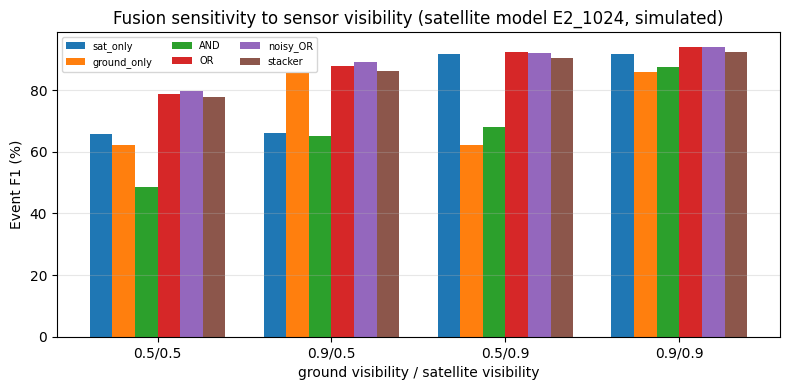


[fusion_E1_640_main] SIMULATED event-level fusion, satellite model E1_640, prevalence 0.5, visibility 0.7/0.7; mean ± std over 20 scenario draws.
       Rule Precision (%) Recall (%)     F1 (%) False-alarm rate (%)
   sat_only    91.3 ± 0.7 69.8 ± 0.9 79.1 ± 0.7            6.8 ± 0.5
ground_only    87.7 ± 0.4 65.5 ± 1.0 75.0 ± 0.7            9.3 ± 0.5
        AND    92.3 ± 0.7 55.5 ± 1.2 69.3 ± 1.0            4.7 ± 0.5
         OR    89.2 ± 0.6 85.8 ± 0.6 87.4 ± 0.5           10.5 ± 0.6
   noisy_OR    88.9 ± 0.6 86.3 ± 0.6 87.6 ± 0.4           10.9 ± 0.6
    stacker    85.4 ± 0.6 85.3 ± 0.7 85.3 ± 0.5           14.7 ± 0.8

[fusion_E1_640_rare] SIMULATED event-level fusion, satellite model E1_640, prevalence 0.1, visibility 0.7/0.7; mean ± std over 20 scenario draws.
       Rule Precision (%) Recall (%)     F1 (%) False-alarm rate (%)
   sat_only    53.7 ± 1.8 69.9 ± 1.6 60.7 ± 1.6            6.7 ± 0.4
ground_only    44.6 ± 1.7 65.1 ± 1.9 52.9 ± 1.5            9.0 ± 0.5
        AND    5

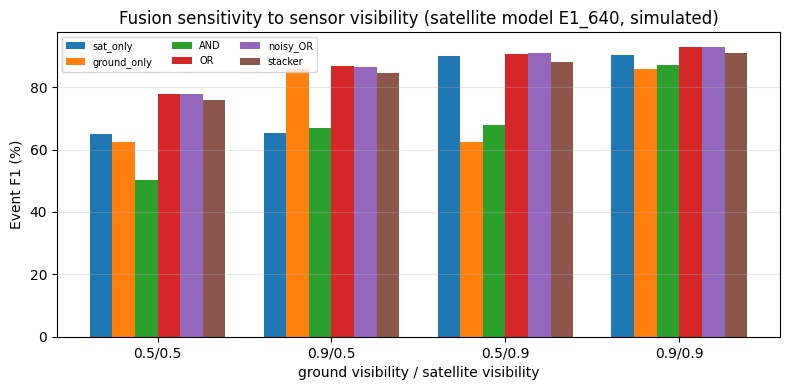


[image_level_auroc] Image-level smoke detection (max smoke confidence per image).
                       Branch AUROC (val) AUROC (test)
     Ground (Branch A, smoke)       0.967        0.945
Satellite (Branch B, E2_1024)       0.991        0.987
 Satellite (Branch B, E1_640)       0.985        0.982


In [25]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

TER, RS = TDIR, RSD
B_MODELS = {"E2_1024": (f"{W}/weights/E2_1024_seed1.pt", 1024),     # main (chosen by rule, not by test result)
            "E1_640":  (f"{W}/weights/E1_640_seed1.pt", 640)}       # light variant
missing = [p for p in [TER, RS] + [p for p, _ in B_MODELS.values()] if not os.path.exists(p)]
assert not missing, f"Missing: {missing}"

EXT = (".jpg", ".jpeg", ".png")
def imgs(d): return sorted(p for p in glob.glob(f"{d}/*") if p.lower().endswith(EXT))
def has_cls(img, cid):
    lp = img.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    if not os.path.exists(lp): return 0
    return int(any(l.split() and int(float(l.split()[0])) == cid for l in open(lp)))

G = {"val": imgs(f"{TER}/valid/images"), "test": imgs(f"{TER}/test/images")}
S = {"val": imgs(f"{RS}/images/val"),    "test": imgs(f"{RS}/images/test")}
Gy = {k: np.array([has_cls(p, 1) for p in v]) for k, v in G.items()}   # ground: Smoke = class 1
Sy = {k: np.array([has_cls(p, 0) for p in v]) for k, v in S.items()}   # satellite: smoke = class 0
rows = [[f"ground {k}", len(G[k]), int(Gy[k].sum()), int((Gy[k] == 0).sum())] for k in G] + \
       [[f"satellite {k}", len(S[k]), int(Sy[k].sum()), int((Sy[k] == 0).sum())] for k in S]
add_table("fusion_pools", pd.DataFrame(rows, columns=["Pool", "Images", "Smoke-positive", "Smoke-negative"]),
          "Image pools for the fusion simulation. Ground negatives are fire-only images (no benign scenes exist in the test set).")

def smoke_scores(model, paths, cid, imgsz, bs=32):
    out = []
    for i in range(0, len(paths), bs):
        for r in model.predict(paths[i:i+bs], imgsz=imgsz, conf=0.001, verbose=False):
            c = r.boxes.cls.cpu().numpy(); s = r.boxes.conf.cpu().numpy()
            m = s[c == cid]
            out.append(float(m.max()) if m.size else 0.0)
    return np.array(out)

def logit(p): p = np.clip(p, 1e-4, 1 - 1e-4); return np.log(p / (1 - p))
def platt(s, y): return LogisticRegression(C=1e6).fit(logit(s)[:, None], y)
def cal(m, s): return m.predict_proba(logit(s)[:, None])[:, 1]

def metrics(pred, y):
    pred, y = np.asarray(pred, bool), np.asarray(y, bool)
    tp = (pred & y).sum(); fp = (pred & ~y).sum(); fn = (~pred & y).sum(); tn = (~pred & ~y).sum()
    p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
    return np.array([p, r, 2 * p * r / max(p + r, 1e-9), fp / max(fp + tn, 1)])   # P, R, F1, false-alarm rate

def scenarios(pg, yg, ps, ys, n, prev, vg, vs, rng):
    E = rng.random(n) < prev                       # event happening?
    def pick(pool, y, vis):
        pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
        see = E & (rng.random(n) < vis)            # sensor sees the smoke with prob = visibility
        return pool[np.where(see, rng.choice(pos, n), rng.choice(neg, n))]
    return E.astype(int), pick(pg, yg, vg), pick(ps, ys, vs)

G1 = np.round(np.arange(0.02, 0.99, 0.01), 2)
G2 = np.arange(0.05, 0.96, 0.05)
def best_t(score, y): return max(G1, key=lambda t: metrics(score >= t, y)[2])

def fit_rules(E, pg, ps):
    R = {}
    t = best_t(ps, E); R["sat_only"] = lambda g, s, t=t: s >= t
    t = best_t(pg, E); R["ground_only"] = lambda g, s, t=t: g >= t
    for name, comb in [("AND", np.logical_and), ("OR", np.logical_or)]:
        _, a, b = max((metrics(comb(pg >= a, ps >= b), E)[2], a, b) for a in G2 for b in G2)
        R[name] = lambda g, s, a=a, b=b, c=comb: c(g >= a, s >= b)
    nor = lambda g, s: 1 - (1 - g) * (1 - s)
    t = best_t(nor(pg, ps), E); R["noisy_OR"] = lambda g, s, t=t: nor(g, s) >= t
    lr = LogisticRegression(C=1.0).fit(np.c_[logit(pg), logit(ps)], E)
    sc = lambda g, s: lr.predict_proba(np.c_[logit(g), logit(s)])[:, 1]
    t = best_t(sc(pg, ps), E); R["stacker"] = lambda g, s, t=t: sc(g, s) >= t
    return R

A = YOLO(A_W)
gs = {k: smoke_scores(A, G[k], 1, 640) for k in G}
AUC_ROWS = [["Ground (Branch A, smoke)", f"{roc_auc_score(Gy['val'], gs['val']):.3f}", f"{roc_auc_score(Gy['test'], gs['test']):.3f}"]]
SS = {}

def run_e5(tag, B_path, B_sz):
    B = YOLO(B_path)
    ss = {k: smoke_scores(B, S[k], 0, B_sz) for k in S}; SS[tag] = ss
    AUC_ROWS.append([f"Satellite (Branch B, {tag})", f"{roc_auc_score(Sy['val'], ss['val']):.3f}", f"{roc_auc_score(Sy['test'], ss['test']):.3f}"])
    pg_ = platt(gs["val"], Gy["val"]); ps_ = platt(ss["val"], Sy["val"])     # calibrate on validation only
    pg = {k: cal(pg_, gs[k]) for k in G}; ps = {k: cal(ps_, ss[k]) for k in S}
    rng = np.random.default_rng(0)
    Ev, gv, sv = scenarios(pg["val"], Gy["val"], ps["val"], Sy["val"], 5000, 0.5, 0.7, 0.7, rng)
    rules = fit_rules(Ev, gv, sv)                                            # thresholds/stacker fitted on validation scenarios

    def evaluate(prev, vg, vs, reps=20):
        out = {k: [] for k in rules}
        for _ in range(reps):
            E, g, s = scenarios(pg["test"], Gy["test"], ps["test"], Sy["test"], 5000, prev, vg, vs, rng)
            for k, f in rules.items(): out[k].append(metrics(f(g, s), E))
        return {k: (np.mean(v, 0) * 100, np.std(v, 0) * 100) for k, v in out.items()}

    res = {}
    for key, (desc, prev, vg, vs) in {"main": ("prevalence 0.5, visibility 0.7/0.7", 0.5, .7, .7),
                                      "rare": ("prevalence 0.1, visibility 0.7/0.7", 0.1, .7, .7)}.items():
        r = evaluate(prev, vg, vs)
        rows = [[k] + [f"{m[i]:.1f} ± {sd[i]:.1f}" for i in range(4)] for k, (m, sd) in r.items()]
        add_table(f"fusion_{tag}_{key}", pd.DataFrame(rows, columns=["Rule", "Precision (%)", "Recall (%)", "F1 (%)", "False-alarm rate (%)"]),
                  f"SIMULATED event-level fusion, satellite model {tag}, {desc}; mean ± std over 20 scenario draws.")
        res[key] = {k: [v[0].tolist(), v[1].tolist()] for k, v in r.items()}
    conds = [(.5, .5), (.9, .5), (.5, .9), (.9, .9)]
    sens = {c: evaluate(0.5, *c) for c in conds}
    rows = [[k] + [f"{sens[c][k][0][2]:.1f}" for c in conds] for k in rules]
    add_table(f"fusion_{tag}_sensitivity", pd.DataFrame(rows, columns=["Rule"] + [f"vis {a}/{b}" for a, b in conds]),
              f"SIMULATED event F1 (%) vs ground/satellite visibility, satellite model {tag}, prevalence 0.5.")
    fig, ax = plt.subplots(figsize=(8, 4)); names = list(rules); wd = 0.13
    for j, k in enumerate(names):
        ax.bar(np.arange(len(conds)) + j * wd, [sens[c][k][0][2] for c in conds], wd, label=k)
    ax.set_xticks(np.arange(len(conds)) + wd * (len(names) - 1) / 2)
    ax.set_xticklabels([f"{a}/{b}" for a, b in conds])
    ax.set_xlabel("ground visibility / satellite visibility"); ax.set_ylabel("Event F1 (%)")
    ax.set_title(f"Fusion sensitivity to sensor visibility (satellite model {tag}, simulated)")
    ax.legend(fontsize=7, ncol=3); ax.grid(axis="y", alpha=0.3); fig.tight_layout()
    fig.savefig(f"{RES}/fusion_sensitivity_{tag}.png", dpi=200); plt.show()
    json.dump({"main_tables": res}, open(f"{RES}/e5_{tag}.json", "w"), indent=1)

for tag, (path, sz) in B_MODELS.items():
    run_e5(tag, path, sz)
add_table("image_level_auroc", pd.DataFrame(AUC_ROWS, columns=["Branch", "AUROC (val)", "AUROC (test)"]),
          "Image-level smoke detection (max smoke confidence per image).")

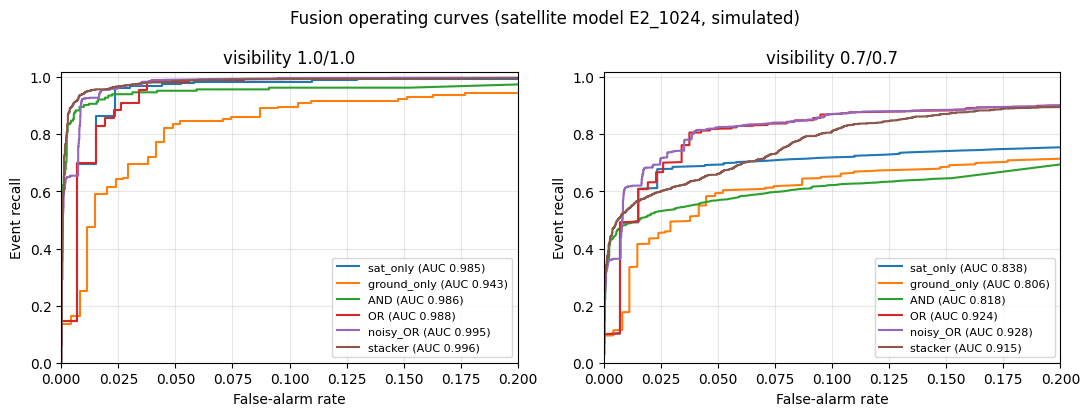


[bootstrap_E2_1024_vis1.0] SIMULATED, satellite model E2_1024, visibility 1.0/1.0: median [95% CI], image bootstrap (B=300).
       Rule                AUROC     Recall@1% FAR      Recall@5% FAR     Recall@10% FAR
   sat_only 0.987 [0.969, 0.998] 73.1 [12.0, 98.0]  98.1 [93.9, 99.8] 99.0 [96.9, 100.0]
ground_only 0.946 [0.921, 0.967] 35.1 [12.2, 69.7]  83.8 [65.7, 89.8]  90.8 [83.2, 95.1]
        AND 0.987 [0.976, 0.995] 90.3 [83.9, 95.1]  95.3 [91.9, 98.3]  96.4 [93.1, 98.9]
         OR 0.990 [0.975, 0.998] 73.2 [12.0, 98.0]  98.8 [89.9, 99.7] 99.8 [98.7, 100.0]
   noisy_OR 0.996 [0.989, 0.999] 93.6 [62.4, 98.9]  99.3 [96.6, 99.9] 99.8 [99.2, 100.0]
    stacker 0.997 [0.992, 0.999] 95.0 [86.6, 98.7] 99.2 [97.4, 100.0] 99.5 [98.3, 100.0]

[paired_E2_1024_vis1.0] SIMULATED paired bootstrap differences, satellite model E2_1024, visibility 1.0/1.0; * = 95% CI excludes 0.
            Comparison              Delta AUROC  Delta recall@5% FAR Delta recall@10% FAR
   noisy_OR - sat_only +0.00

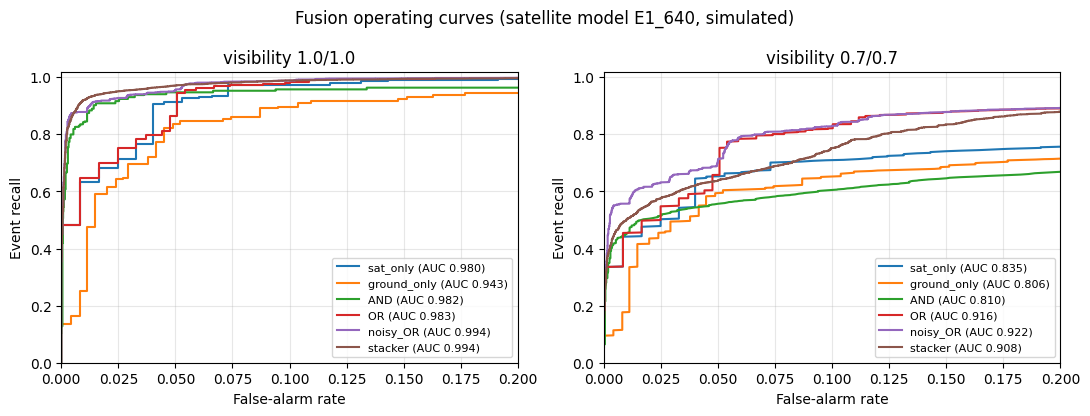


[bootstrap_E1_640_vis1.0] SIMULATED, satellite model E1_640, visibility 1.0/1.0: median [95% CI], image bootstrap (B=300).
       Rule                AUROC     Recall@1% FAR     Recall@5% FAR    Recall@10% FAR
   sat_only 0.982 [0.968, 0.993] 65.4 [44.2, 90.7] 92.7 [71.1, 98.5] 97.6 [93.0, 99.7]
ground_only 0.946 [0.921, 0.967] 35.1 [12.2, 69.7] 83.8 [65.7, 89.8] 90.8 [83.2, 95.1]
        AND 0.983 [0.972, 0.992] 86.6 [77.4, 93.7] 94.6 [91.0, 98.0] 95.6 [92.1, 98.3]
         OR 0.986 [0.974, 0.994] 66.8 [44.2, 82.3] 95.8 [74.5, 98.8] 99.0 [95.8, 99.8]
   noisy_OR 0.995 [0.991, 0.998] 90.5 [85.3, 95.7] 97.8 [93.3, 99.4] 99.3 [98.0, 99.9]
    stacker 0.995 [0.991, 0.998] 92.5 [86.4, 96.8] 98.1 [95.7, 99.5] 99.3 [97.9, 99.9]

[paired_E1_640_vis1.0] SIMULATED paired bootstrap differences, satellite model E1_640, visibility 1.0/1.0; * = 95% CI excludes 0.
            Comparison              Delta AUROC  Delta recall@5% FAR Delta recall@10% FAR
   noisy_OR - sat_only +0.012 [+0.004, +0.022]

In [26]:
from sklearn.metrics import roc_curve

def rule_scores(g, s, lr):
    return {"sat_only": s, "ground_only": g, "AND": np.minimum(g, s), "OR": np.maximum(g, s),
            "noisy_OR": 1 - (1 - g) * (1 - s), "stacker": lr.predict_proba(np.c_[logit(g), logit(s)])[:, 1]}

def calibrated(ss):
    pg_ = platt(gs["val"], Gy["val"]); ps_ = platt(ss["val"], Sy["val"])
    return {k: cal(pg_, gs[k]) for k in G}, {k: cal(ps_, ss[k]) for k in S}

def op_curves(ss, vg, vs, prev=0.5, n=20000, seed=1):
    pg, ps = calibrated(ss); rng = np.random.default_rng(seed)
    Ev, gv, sv = scenarios(pg["val"], Gy["val"], ps["val"], Sy["val"], 5000, 0.5, vg, vs, rng)
    lr = LogisticRegression().fit(np.c_[logit(gv), logit(sv)], Ev)
    E, g, s = scenarios(pg["test"], Gy["test"], ps["test"], Sy["test"], n, prev, vg, vs, rng)
    out = {}
    for k, sc in rule_scores(g, s, lr).items():
        fpr, tpr, _ = roc_curve(E, sc); out[k] = (fpr, tpr, roc_auc_score(E, sc))
    return out

def boot_raw(ss, vg, vs, B=300, n=5000, seed=11):
    rng = np.random.default_rng(seed); pg, ps = calibrated(ss)
    Ev, gv, sv = scenarios(pg["val"], Gy["val"], ps["val"], Sy["val"], 5000, 0.5, vg, vs, rng)
    lr = LogisticRegression().fit(np.c_[logit(gv), logit(sv)], Ev)          # fixed, fitted on validation only
    res = {k: [] for k in ["sat_only", "ground_only", "AND", "OR", "noisy_OR", "stacker"]}
    for _ in range(B):
        gi = rng.integers(0, len(pg["test"]), len(pg["test"]))               # resample test IMAGES
        si = rng.integers(0, len(ps["test"]), len(ps["test"]))
        E, g, s = scenarios(pg["test"][gi], Gy["test"][gi], ps["test"][si], Sy["test"][si], n, 0.5, vg, vs, rng)
        for k, v in rule_scores(g, s, lr).items():
            fpr, tpr, _ = roc_curve(E, v)
            res[k].append([roc_auc_score(E, v)] + [np.interp(f, fpr, tpr) * 100 for f in (0.01, 0.05, 0.10)])
    return {k: np.array(v) for k, v in res.items()}      # columns: AUROC, rec@1%, rec@5%, rec@10%

def ci(x, auc=False):
    lo, med, hi = np.percentile(x, [2.5, 50, 97.5])
    return f"{med:.3f} [{lo:.3f}, {hi:.3f}]" if auc else f"{med:.1f} [{lo:.1f}, {hi:.1f}]"

pairs = [("noisy_OR", "sat_only"), ("stacker", "sat_only"), ("noisy_OR", "ground_only"), ("noisy_OR", "stacker"), ("noisy_OR", "OR")]
for tag in B_MODELS:
    ss = SS[tag]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    for ax, (vg, vs) in zip(axes, [(1.0, 1.0), (0.7, 0.7)]):
        for k, (fpr, tpr, auc) in op_curves(ss, vg, vs).items(): ax.plot(fpr, tpr, label=f"{k} (AUC {auc:.3f})")
        ax.set_xlim(0, 0.2); ax.set_ylim(0, 1.02); ax.set_xlabel("False-alarm rate"); ax.set_ylabel("Event recall")
        ax.set_title(f"visibility {vg}/{vs}"); ax.legend(fontsize=8, loc="lower right"); ax.grid(alpha=0.3)
    fig.suptitle(f"Fusion operating curves (satellite model {tag}, simulated)")
    fig.tight_layout(); fig.savefig(f"{RES}/e5_roc_{tag}.png", dpi=200); plt.show()
    for vg, vs in [(1.0, 1.0), (0.7, 0.7)]:
        R = boot_raw(ss, vg, vs)
        rows = [[k, ci(a[:, 0], True), ci(a[:, 1]), ci(a[:, 2]), ci(a[:, 3])] for k, a in R.items()]
        add_table(f"bootstrap_{tag}_vis{vg}", pd.DataFrame(rows, columns=["Rule", "AUROC", "Recall@1% FAR", "Recall@5% FAR", "Recall@10% FAR"]),
                  f"SIMULATED, satellite model {tag}, visibility {vg}/{vs}: median [95% CI], image bootstrap (B=300).")
        rows = []
        for a, b in pairs:
            row = [f"{a} - {b}"]
            for j, auc in [(0, True), (2, False), (3, False)]:
                d = R[a][:, j] - R[b][:, j]; lo, med, hi = np.percentile(d, [2.5, 50, 97.5]); star = "*" if (lo > 0 or hi < 0) else ""
                row.append((f"{med:+.3f} [{lo:+.3f}, {hi:+.3f}]" if auc else f"{med:+.1f} [{lo:+.1f}, {hi:+.1f}]") + star)
            rows.append(row)
        add_table(f"paired_{tag}_vis{vg}", pd.DataFrame(rows, columns=["Comparison", "Delta AUROC", "Delta recall@5% FAR", "Delta recall@10% FAR"]),
                  f"SIMULATED paired bootstrap differences, satellite model {tag}, visibility {vg}/{vs}; * = 95% CI excludes 0.")

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5514.0±1162.5 MB/s, size: 1628.2 KB)
val: Scanning /kaggle/working/fasdd_rs_yolo/labels/test... 370 images, 148 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 370/370 92.5it/s 4.0s0.0ss
val: New cache created: /kaggle/working/fasdd_rs_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 2.7it/s 9.0s0.3s
                   all        370        473       0.69      0.691       0.71      0.409
Speed: 4.1ms preprocess, 10.9ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/results/plots/branchB_E2_test


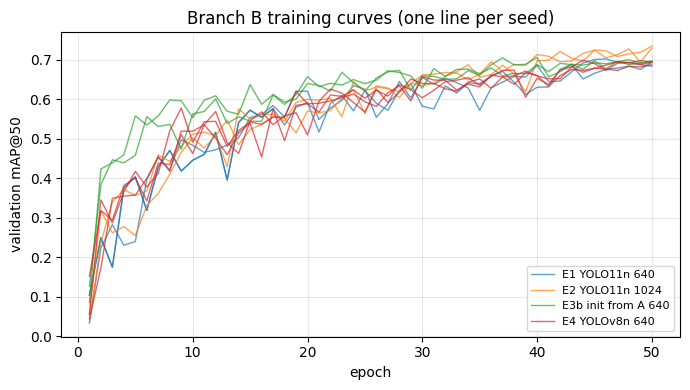

In [27]:
B2 = YOLO(f"{W}/weights/E2_1024_seed1.pt")
_ = B2.val(data=f"{RSD}/data.yaml", split="test", imgsz=1024, plots=True,
           project=f"{RES}/plots", name="branchB_E2_test", exist_ok=True)

groups = {"e1_": "E1 YOLO11n 640", "e2_": "E2 YOLO11n 1024", "e3b_": "E3b init from A 640", "e4_": "E4 YOLOv8n 640"}
colors = {"e1_": "C0", "e2_": "C1", "e3b_": "C2", "e4_": "C3"}
fig, ax = plt.subplots(figsize=(7, 4)); seen = set()
for f in sorted(glob.glob(f"{W}/runs/*/results.csv")):
    run = os.path.basename(os.path.dirname(f)); key = next((k for k in groups if run.startswith(k)), None)
    if key is None: continue
    df = pd.read_csv(f); df.columns = [c.strip() for c in df.columns]
    if "metrics/mAP50(B)" not in df: continue
    ax.plot(df["epoch"], df["metrics/mAP50(B)"], color=colors[key], alpha=0.7, lw=1, label=groups[key] if key not in seen else None)
    seen.add(key)
if seen:
    ax.set_xlabel("epoch"); ax.set_ylabel("validation mAP@50"); ax.set_title("Branch B training curves (one line per seed)")
    ax.legend(fontsize=8); ax.grid(alpha=0.3); fig.tight_layout(); fig.savefig(f"{RES}/branchB_training_curves.png", dpi=200); plt.show()
else:
    print("no results.csv found in runs/ (training logs were not in the backup)")

In [28]:
def eff_row(label, wpath, imgsz, paths, n=100, warm=10):
    m = YOLO(wpath)
    try:
        info = m.info(verbose=False, imgsz=imgsz); gflops = info[3] if info else float("nan")
    except Exception:
        gflops = float("nan")
    params = sum(p.numel() for p in m.model.parameters())
    for p in paths[:warm]: m.predict(p, imgsz=imgsz, verbose=False)
    t = [sum(m.predict(p, imgsz=imgsz, verbose=False)[0].speed.values()) for p in paths[warm:warm + n]]
    return [label, f"{params/1e6:.2f}", f"{gflops:.1f}", f"{np.mean(t):.1f} ± {np.std(t):.1f}"]

rows = [eff_row("Branch A, 640 px (terrestrial images)", A_W, 640, G["test"]),
        eff_row("Branch B (E1), 640 px (satellite images)", B_MODELS["E1_640"][0], 640, S["test"]),
        eff_row("Branch B (E2), 1024 px (satellite images)", B_MODELS["E2_1024"][0], 1024, S["test"])]
add_table("efficiency", pd.DataFrame(rows, columns=["Model", "Params (M)", "GFLOPs", "Latency ms/img (T4, batch 1)"]),
          "Model size and end-to-end latency (preprocess + inference + postprocess), mean ± std over 100 test images.")


[efficiency] Model size and end-to-end latency (preprocess + inference + postprocess), mean ± std over 100 test images.
                                    Model Params (M) GFLOPs Latency ms/img (T4, batch 1)
    Branch A, 640 px (terrestrial images)       2.61    nan                    9.5 ± 1.0
 Branch B (E1), 640 px (satellite images)       2.60    nan                   10.5 ± 0.4
Branch B (E2), 1024 px (satellite images)       2.60    nan                   19.0 ± 0.3


Satellite branch (YOLO11n, 1024 px), FASDD_RS test {'True positive': 218, 'Missed (false negative)': 4, 'False alarm (false positive)': 7} | true negatives: 141


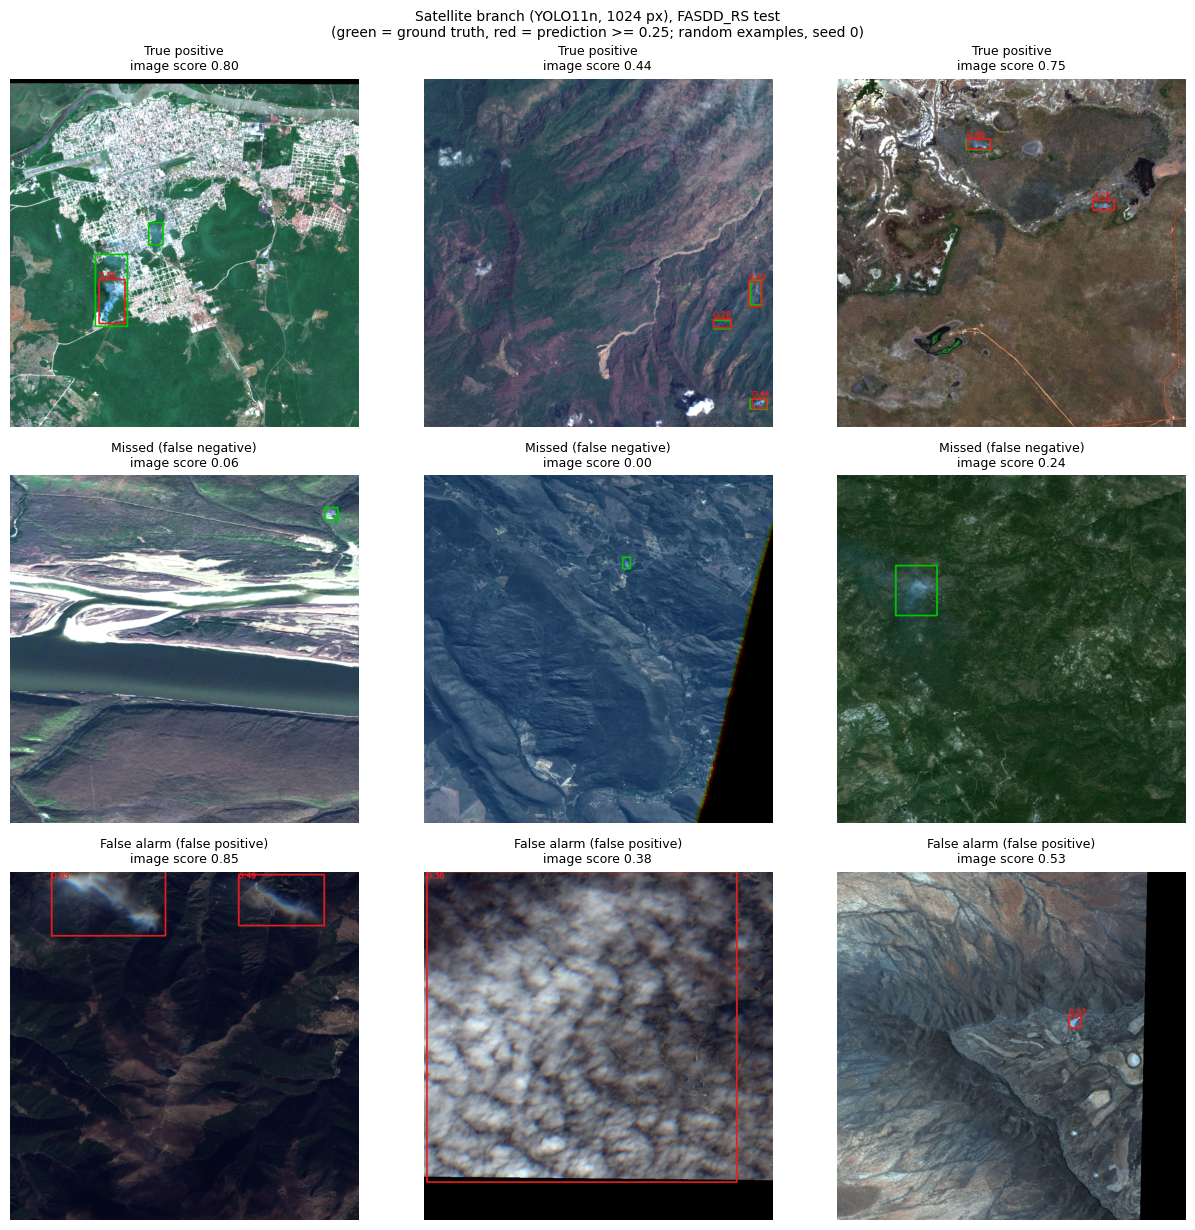

Ground branch (YOLO11n, 640 px), smoke class, test {'True positive': 121, 'Missed (false negative)': 40, 'False alarm (false positive)': 11} | true negatives: 263


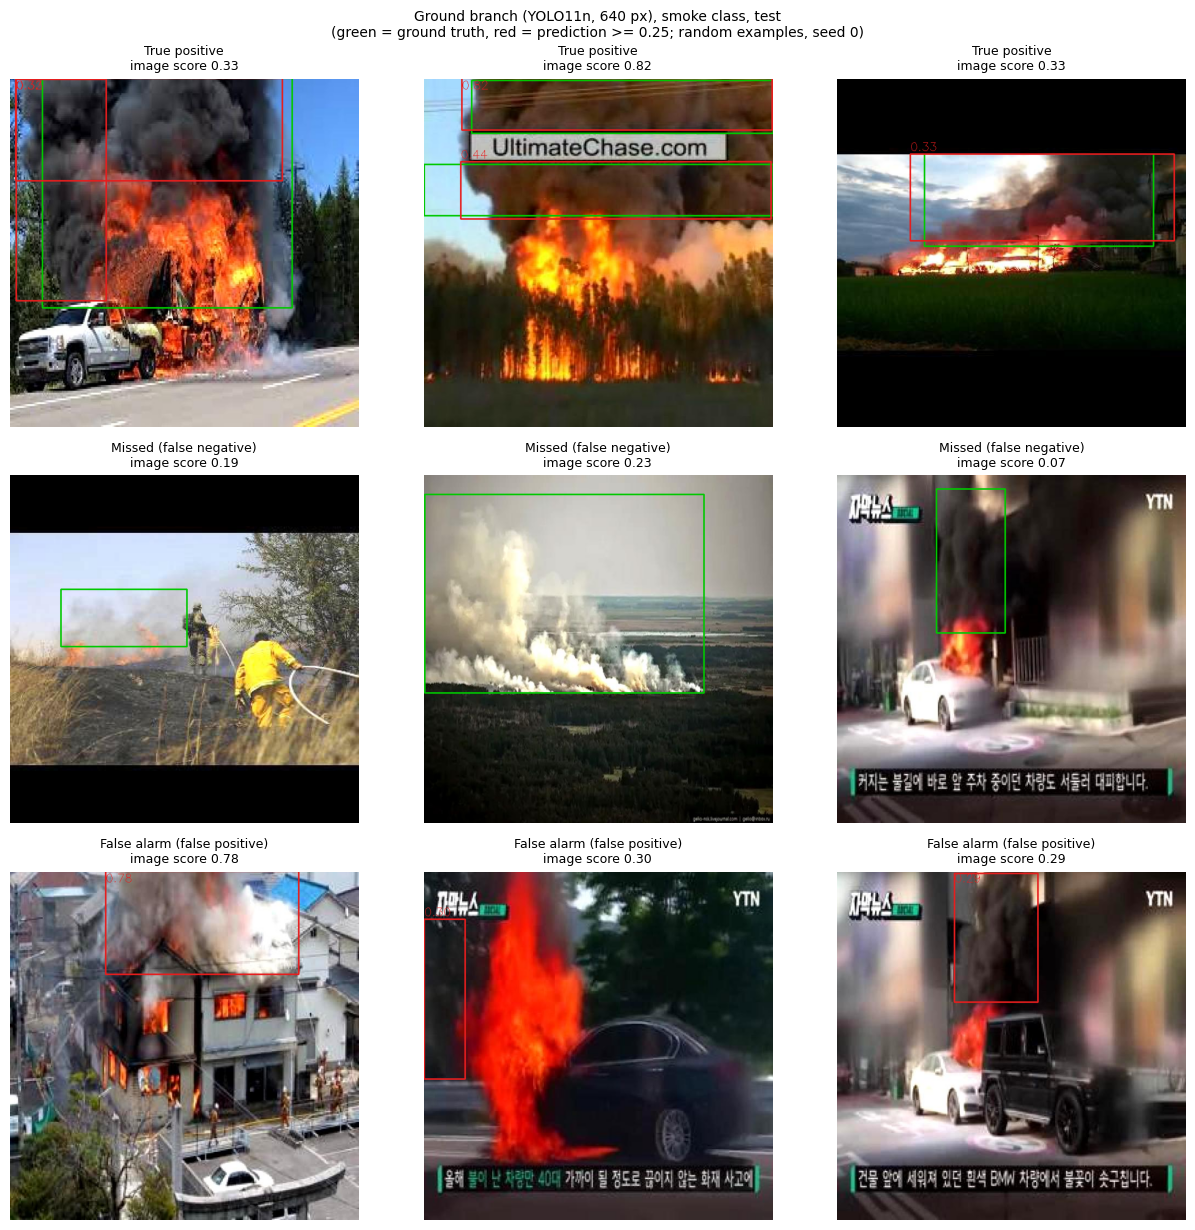


[image_level_counts] Image-level outcomes at a 0.25 confidence threshold (smoke).
                                            Branch  True positives  Misses  False alarms  True negatives
Satellite branch (YOLO11n, 1024 px), FASDD_RS test             218       4             7             141
Ground branch (YOLO11n, 640 px), smoke class, test             121      40            11             263


In [29]:
import random

def draw_boxes(img, lab_path, cid_label, boxes, confs, thr):
    h, w = img.shape[:2]; t = max(2, w // 250)
    if os.path.exists(lab_path):
        for l in open(lab_path):
            p = l.split()
            if len(p) >= 5 and int(float(p[0])) == cid_label:
                xc, yc, bw, bh = map(float, p[1:5])
                cv2.rectangle(img, (int((xc-bw/2)*w), int((yc-bh/2)*h)), (int((xc+bw/2)*w), int((yc+bh/2)*h)), (0, 200, 0), t)
    for (x1, y1, x2, y2), c in zip(boxes, confs):
        if c >= thr:
            cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (230, 30, 30), t)
            cv2.putText(img, f"{c:.2f}", (int(x1), max(int(y1) - 6, 20)), cv2.FONT_HERSHEY_SIMPLEX,
                        max(0.7, w / 1400), (230, 30, 30), max(1, w // 400))
    return img

def qual_fig(model, paths, y, scores, cid_model, cid_label, imgsz, title, outfile, k=3, thr=0.25, seed=0):
    groups_ = {"True positive": [i for i in range(len(y)) if y[i] == 1 and scores[i] >= thr],
               "Missed (false negative)": [i for i in range(len(y)) if y[i] == 1 and scores[i] < thr],
               "False alarm (false positive)": [i for i in range(len(y)) if y[i] == 0 and scores[i] >= thr]}
    tn = sum(1 for i in range(len(y)) if y[i] == 0 and scores[i] < thr)
    counts = {n: len(v) for n, v in groups_.items()}
    print(title, counts, "| true negatives:", tn)
    rng = random.Random(seed)
    fig, axes = plt.subplots(3, k, figsize=(4.2 * k, 12.5))
    for r, (name, idx) in enumerate(groups_.items()):
        chosen = rng.sample(idx, min(k, len(idx)))
        for c in range(k):
            ax = axes[r, c]; ax.axis("off")
            if c >= len(chosen): continue
            p = paths[chosen[c]]
            res = model.predict(p, imgsz=imgsz, conf=0.001, verbose=False)[0]
            m = res.boxes.cls.cpu().numpy() == cid_model
            img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
            lab = p.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
            img = draw_boxes(img, lab, cid_label, res.boxes.xyxy.cpu().numpy()[m], res.boxes.conf.cpu().numpy()[m], thr)
            ax.imshow(img); ax.set_title(f"{name}\nimage score {scores[chosen[c]]:.2f}", fontsize=9)
    fig.suptitle(f"{title}\n(green = ground truth, red = prediction >= {thr}; random examples, seed {seed})", fontsize=10)
    fig.tight_layout(); fig.savefig(outfile, dpi=200); plt.show()
    return [title, counts["True positive"], counts["Missed (false negative)"], counts["False alarm (false positive)"], tn]

ss2 = SS["E2_1024"]["test"]
rows = [qual_fig(B2, S["test"], Sy["test"], ss2, 0, 0, 1024, "Satellite branch (YOLO11n, 1024 px), FASDD_RS test", f"{RES}/e6_satellite.png"),
        qual_fig(A, G["test"], Gy["test"], gs["test"], 1, 1, 640, "Ground branch (YOLO11n, 640 px), smoke class, test", f"{RES}/e6_ground.png")]
add_table("image_level_counts", pd.DataFrame(rows, columns=["Branch", "True positives", "Misses", "False alarms", "True negatives"]),
          "Image-level outcomes at a 0.25 confidence threshold (smoke).")

In [30]:
export_tables()
shutil.make_archive(f"{W}/paper_outputs", "zip", RES)
print(sorted(os.listdir(RES)))
print("zip size MB:", round(os.path.getsize(f"{W}/paper_outputs.zip") / 1e6, 1))

['E1_640_seed1.json', 'E1_640_seed2.json', 'E1_640_seed42.json', 'E2_1024_seed1.json', 'E2_1024_seed2.json', 'E2_1024_seed42.json', 'E3b_640_seed1.json', 'E3b_640_seed2.json', 'E3b_640_seed42.json', 'E4_v8n_640_seed1.json', 'E4_v8n_640_seed2.json', 'E4_v8n_640_seed42.json', 'branchB_training_curves.png', 'e5_E1_640.json', 'e5_E2_1024.json', 'e5_roc_E1_640.png', 'e5_roc_E2_1024.png', 'e6_ground.png', 'e6_satellite.png', 'fusion_sensitivity_E1_640.png', 'fusion_sensitivity_E2_1024.png', 'paper_tables.md', 'paper_tables.tex', 'plots', 'table_bootstrap_E1_640_vis0.7.csv', 'table_bootstrap_E1_640_vis1.0.csv', 'table_bootstrap_E2_1024_vis0.7.csv', 'table_bootstrap_E2_1024_vis1.0.csv', 'table_branchA_results.csv', 'table_branchB_results.csv', 'table_cross_domain.csv', 'table_dataset_satellite.csv', 'table_dataset_terrestrial.csv', 'table_efficiency.csv', 'table_environment.csv', 'table_fusion_E1_640_main.csv', 'table_fusion_E1_640_rare.csv', 'table_fusion_E1_640_sensitivity.csv', 'table_fusio